# Part 1. Set up the notebook
Copyright (C) 2026 Marianna Foschi, Antonio Fuentes, Brandon Zhao

This program is free software: you can redistribute it and/or modify it under the terms of the GNU General Public License as published by the Free Software Foundation, either version 3 of the License, or (at your option) any later version.

This program is distributed in the hope that it will be useful, but WITHOUT ANY WARRANTY; without even the implied warranty of MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the GNU General Public License for more details.

You should have received a copy of the GNU General Public License along with this program. If not, see <https://www.gnu.org/licenses/>.

Reference: Foschi, M., Zhao, B., Fuentes, A. et al., "Video reconstruction of variable VLBI observations with neural fields." Under rev. (2026)

### Step 1: Enable the GPU runtime

1. In the Colab menu, click Runtime → Change runtime type
2. Under "Hardware accelerator", select T4 GPU
3. Click Save

### Step 2: Install packages

1. Run the following cell
2. A pop up window should appear, select "Restart session"
3. Run the cell again

In [2]:
!pip install git+https://github.com/mariannafoschi/kine.git
!pip install jax[cuda12] -f https://storage.googleapis.com/jax-releases/jax_cuda_releases.html
!pip install ehtim finufft flax optax

  Cloning https://github.com/mariannafoschi/kine.git to /tmp/pip-req-build-o7tp94nq
  Running command git clone --filter=blob:none --quiet https://github.com/mariannafoschi/kine.git /tmp/pip-req-build-o7tp94nq
  Resolved https://github.com/mariannafoschi/kine.git to commit 0a68127da08c778727bb8b28677dc0625decd0a2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Looking in links: https://storage.googleapis.com/jax-releases/jax_cuda_releases.html


### Step 3: Import packages

Ensure all packages load correctly

In [3]:
import glob
import numpy as np
import ehtim as eh
import ehtim.const_def as ehc
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage
from tqdm.notebook import tqdm
from collections import OrderedDict as odict

import jax
import optax
from flax import linen as nn
from jax import numpy as jnp

import kine.model as mo
import kine.obsdata as ob
import kine.trainer as tr
import kine.utils as ut
import kine.video as vi

print("✓ All imports successful")

Welcome to eht-imaging! v 1.3.2 


✓ All imports successful


**Note:** GPU-accelerated NUFFT is not available in colab but it is implemented in the code. It is designed for multi-epoch imaging of large datasets.

# Part 2. Upload observations and set imaging parameters
### Step 1: Upload observation file to Colab
Run the following cell and click "Choose Files" to select the observations to image. To follow thi tutorial, select any of the observations in the folder "data" of the Kine repository.

In [4]:
from google.colab import files
uploaded = files.upload()

Saving eht_m87_2017-04-11.uvfits to eht_m87_2017-04-11.uvfits
Saving eht_m87_2017-04-10.uvfits to eht_m87_2017-04-10.uvfits
Saving eht_m87_2017-04-08.uvfits to eht_m87_2017-04-08.uvfits
Saving eht_m87_2017-04-07.uvfits to eht_m87_2017-04-07.uvfits


### Step 2: Set imaging parameters
**Note:** In the actual code this is done by loading a .yaml file, but for this Colab tutorial they are set directly in the notebook.

In [5]:
# Data pre-processing
# -----------------------------
# Time averaging
tavg = 60
# Systematic noise
syserr = 0.01
# Minimum number of baselines per data snapshot
min_bl = 0

# Coordinates and data products
# -----------------------------
# Field of view (uas)
fov_uas = 160
# Space resolution (pix)
npix = 64
npix_out = 128
# Data products
data_prod = ['cphaseI', 'logcampI']

# Network initialization
# -----------------------------
init_params = {
  'fwhm': 80,
  'blur': 20,
  'posx': 0,
  'posy': 0
}
# Training
# -----------------------------
# Initialization seed
seed = 1
# Number of epochs
niter = 2500
initniter = 2000
# Degrees of positional encoding ([t, x, y])
nposenc = [0, 0]
# Network parameters
depth = 4
width = 256
outshift = 10
scaling_i = 1

# Part 3. Run the algorithm
### Step 1: Load and preprocess the observations

In [6]:
# Set random keys
rkey = jax.random.PRNGKey(seed)
np.random.seed(seed)

print('Loading data...')

# Load and pre-process data
obs = ob.Obsdata.load_uvfits('eht_m87_2017-04-10.uvfits')
obs = obs.avg_coherent(tavg)
obs = obs.add_fractional_noise(syserr)

# Get zbl flux density)
totflux = obs.get_zbl()

Loading data...
Loading uvfits:  eht_m87_2017-04-10.uvfits
no IF in uvfits header!
POLREP_UVFITS: circ
Number of uvfits Correlation Products: 4


/usr/local/lib/python3.11/dist-packages/ehtim/io/load.py:1419: RuntimeWarning: invalid value encountered in divide
  rr = (np.nansum(np.nansum(rr_2d * rrweight, axis=2), axis=1) /
/usr/local/lib/python3.11/dist-packages/ehtim/io/load.py:1423: RuntimeWarning: invalid value encountered in divide
  rl = (np.nansum(np.nansum(rl_2d * rlweight, axis=2), axis=1) /
/usr/local/lib/python3.11/dist-packages/ehtim/io/load.py:1425: RuntimeWarning: invalid value encountered in divide
  lr = (np.nansum(np.nansum(lr_2d * lrweight, axis=2), axis=1) /
/usr/local/lib/python3.11/dist-packages/ehtim/statistics/dataframes.py:198: FutureWarning: The provided callable <function min at 0x7e4672d9cae0> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  vis_avg = vis.groupby(grouping).agg(aggregated).reset_index()
/usr/local/lib/python3.11/dist-packages/ehtim/statistics/dataframes.py:198: Futu

### Step 2: Prepare the grid of input coordinates, extract the data products and the matrices for the Fourier transform.

In [7]:
# Set up grid of input coordinates and data products
print('Set up grid of input coordinates...')

# Field of view
fov = fov_uas * eh.RADPERUAS

# Set 2D coordinate grids
grid = ut.get_grid(npix, npix)

# Set polarization channels
outdim = 1
if 'visQ' in data_prod: outdim = 4
if 'visV' in data_prod: outdim = 5

# Set empty image for image metadata and dimensions
improxy = eh.image.make_square(obs, npix, fov, pol_prim='I')

# Compute lists of data products (target), uncertainties (sigma),
# and Fourier matrix (A) at each observed time
print('Retrieving data products from each epoch...')

data = {}
for dtype in data_prod:
    target, sigma, A = ob.Obsdata.get_data(obs, dtype, improxy)
    data[dtype] = {
        'target': target,
        'sigma': sigma,
        'A': A
    }
    del target, sigma, A

Set up grid of input coordinates...
Retrieving data products from each epoch...


### Step 3: Define the neural network architecture

In [8]:
# Neural Field
network = mo.NeuralField(
    posenc_deg=tuple(nposenc),
    outdim=outdim,
    depth=depth,
    width=width,
    activ=nn.gelu,
    outactiv=nn.sigmoid,
    outshift=outshift,
    scaling_i=scaling_i
)
params = network.init(rkey, jnp.ones([grid.shape[-1]]), train=True)
batch_stats = network.init(rkey, jnp.ones([grid.shape[-1]]), train=True)

# Schedule and train state
sched = optax.piecewise_constant_schedule(
init_value=1e-2,
    boundaries_and_scales={initniter: 0.1}
)
state = tr.Trainer.create(
    apply_fn=network.apply,
    params=params['params'],
    batch_stats=batch_stats['batch_stats'],
    tx=optax.adamax(sched)
)


### Step 4: Run the initialization

Initialization...


  0%|          | 0/2000 [00:00<?, ?it/s]

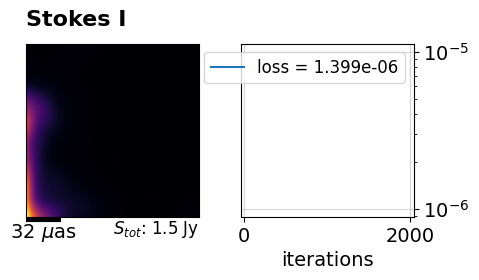

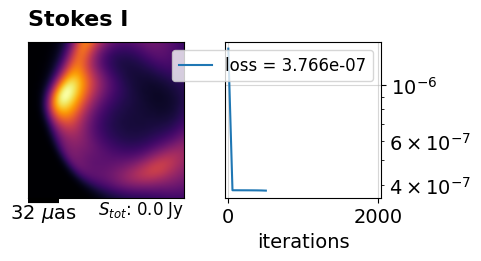

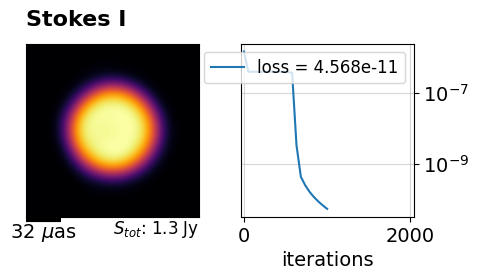

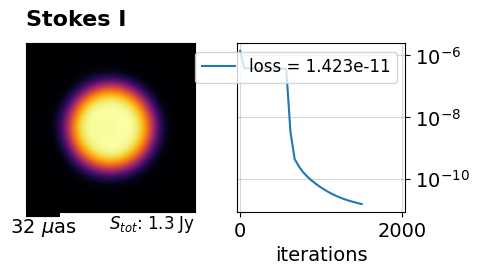

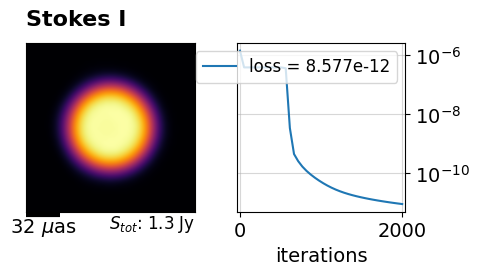

In [11]:
# Show progress updates
def show_progress(image, outpath):
    image.plot(outpath=outpath)
    display(IPImage(outpath))
    plt.close('all')

# Fix jax version issue (Only needed in Colab)
if not hasattr(jax, 'tree_map'):
    jax.tree_map = jax.tree.map

print('Initialization...')

# Create initialization image
init_im = vi.Image(npix, fov, obs.ra, obs.dec, initniter)
init_im.add_tophat(totflux, init_params)
init_im.plot(outpath='./init_image.png')

# Create empty Image object and initialize loss function
# Initialize image and loss
init = vi.Image(npix, fov, obs.ra, obs.dec, initniter)
lloss, loss = [], 0

# Initialization training
for i in (pbar := tqdm(range(1, initniter+1))):
    pbar.set_description(f'Loss {loss:.1e}')

    # Apply one training step
    loss, _, out, state = tr.Trainer.train_step(
        odict(
            state=state,
            grid=grid,
            init_arr=init_im.iarr,
            # init_img=init_im.iarr
        )
    )

    # Save loss
    lloss.append(loss)

    # Show initialization progress
    if i == 1 or i % 500 == 0 or i == initniter:
        init.from_image(out, loss=lloss)
        show_progress(image=init, outpath='./output_init.png')

### Step 5: Run the optimization

Training...


  0%|          | 0/2500 [00:00<?, ?it/s]

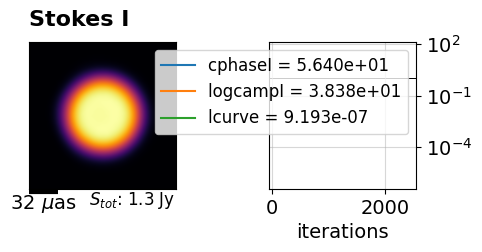

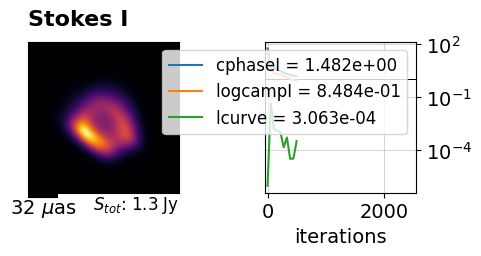

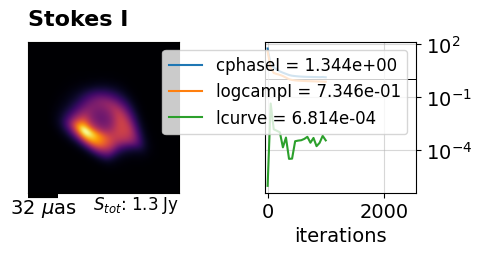

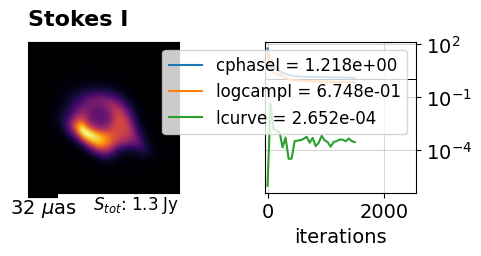

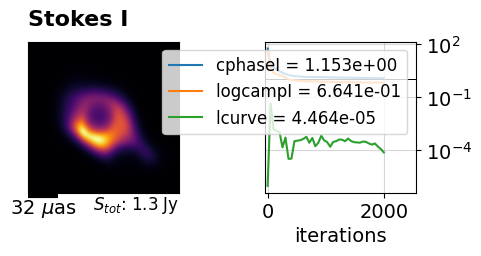

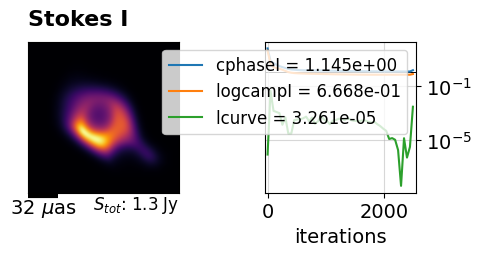

In [12]:
print('Training...')

# Create empty Image object and initialize loss function
image = vi.Image(npix, fov, obs.ra, obs.dec, niter)
lloss, loss = {dp: [] for dp in data_prod} | {'lcurve': []}, 0

# Optimization training
for i in (pbar := tqdm(range(1, niter+1))):
    pbar.set_description(f'Loss {loss:.1e}')

    # Apply one training step
    loss, ldict, out, state = tr.Trainer.train_step(
        odict(
            state=state,
            grid=grid,
            data=data,
            lcurve=jnp.array([totflux]),
        )
    )

    # Save loss
    for l in lloss.keys():
        lloss[l].append(ldict[l])

    # Show initialization progress
    if i == 1 or i % 500 == 0 or i == initniter:
        image.from_image(out, loss=lloss)
        show_progress(image=image, outpath='./output_train.png')

### Step 6: Save the final image
1. Resample the network on a finer spatial grid
2. Save the final image

Saving results...


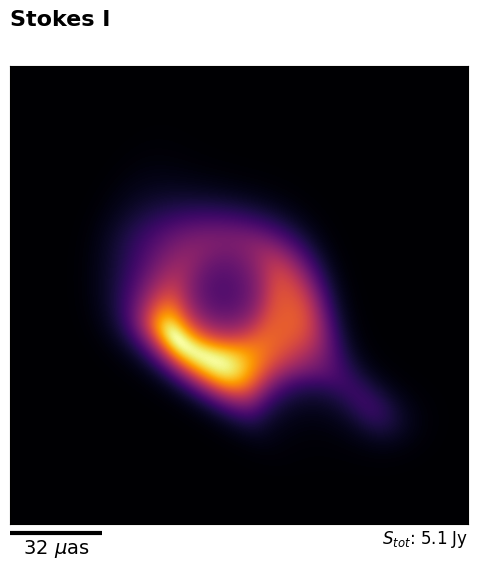

In [13]:
# Save image after optimization
print('Saving results...')

# Sample output image on a finer grid
grid_out = ut.get_grid(npix_out, npix_out)

# Generate output image
image = vi.Image(npix_out, fov, obs.ra, obs.dec, niter)
image.from_state(state, grid_out)
image.plot(outpath='./output_image.png')
image.save_fits('./output_image.fits')
display(IPImage('./output_image.png'))
plt.close('all')